In [20]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from dataclasses import dataclass
import seaborn as sns

In [8]:
@dataclass
class Config:
    grid_size: int = 100
    iterations: int = 100
    delta: float = 0.1

config = Config()
config

Config(grid_size=100, iterations=100, delta=0.1)

In [3]:
grid_size = 100

In [103]:
class ContinuousRecursion:
    def __init__(self, config: Config) -> None:
        self.grid_size = config.grid_size
        self.iterations = config.iterations
        self.delta = config.delta
        self.X, self.Y = self.init_mesh()
        self.seed()

    def init_mesh(self) -> tuple:
        x = np.linspace(-np.pi, np.pi, self.grid_size)
        y = np.linspace(-np.pi, np.pi, self.grid_size)
        X, Y = np.meshgrid(x, y)
        return X, Y

    def seed(self):
        self.F = np.zeros((self.grid_size, self.grid_size))
        center = self.grid_size // 2
        self.F[center, center] = 1

    def update_field(self, delta: float) -> np.ndarray:
        return np.sin(self.X * delta) / self.Y / np.sin(self.Y * delta / self.X)

In [104]:
cr = ContinuousRecursion(config)

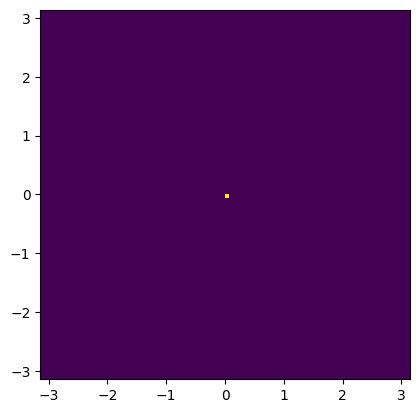

In [123]:
F = cr.F
delta = config.delta
fig, ax = plt.subplots()
img = ax.imshow(F, extent=[-np.pi, np.pi, -np.pi, np.pi], cmap='viridis', animated=True);

def update(frame):
    global F, delta
    F = cr.update_field(delta + delta * frame)
    img.set_data(F)
    return [img]

In [124]:
ani = FuncAnimation(fig, update, frames=config.iterations, blit=True)

# Display the animation
from IPython.display import HTML
HTML(ani.to_jshtml())